# Notebook 03: How sure can we be? Statistics on the simulation

**Project:** Hacker Statistics, chances of winning a bet  
**Notebook 01** simulated the bet. **Notebook 02** found the exact answer (77.67%). This notebook asks the question every real analysis faces, where there is *no* exact answer to peek at: **how much should we trust a number that comes from a sample?** Here we can check every statistical method against the truth, which is rare and makes this a good place to learn them.

Methods covered, each with `scipy` or `statsmodels`: four kinds of confidence interval (and how often each one is right), a Bayesian update, a goodness-of-fit test of the whole simulation, a two-proportion test with a power calculation, and a check on what a "5% false alarm" really means.

**How each section is laid out:** what we are looking for, the code, its result, how to read it, what it means, and what's next and why.

## 1. Setup

### What we are looking for
Imports, the project's own functions, and the one number we will treat as the truth: the exact chance of winning from notebook 02.

In [1]:
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.proportion import proportion_confint, proportions_ztest, proportion_effectsize
from statsmodels.stats.power import NormalIndPower

ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.hacker_stats import simulate, win_chance, exact_distribution, exact_win_chance

RED, BLUE, GREY, GOLD = "#9A3B2E", "#2F6690", "#a39b93", "#A87613"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})

ROLLS, TARGET, CLUMSY = 100, 60, 0.001
TRUTH = exact_win_chance(ROLLS, TARGET, CLUMSY)
print(f"The exact chance of winning (from notebook 02): {TRUTH:.4%}")

The exact chance of winning (from notebook 02): 77.6691%


### How to read it
One line: the exact answer, 77.67%. In real projects you would not have this. Here it is our answer key.

### What it means
Every method below is scored against this number. A method that claims "95% sure" had better capture 77.67% about 95 times in 100.

### What's next and why
We start with the most common thing anyone does with a sample: put a margin of error around it.

## 2. Four confidence intervals, and which one to trust

### What we are looking for
A 95% confidence interval is a promise: if you repeated the whole experiment many times, about 95% of the intervals would contain the true value. Different formulas keep that promise differently. We compare four on one sample, then test the promise itself.

- **Normal (Wald):** the textbook "estimate plus or minus 1.96 standard errors".
- **Wilson:** a refinement that behaves better with small samples.
- **Clopper-Pearson (exact binomial):** guaranteed never to promise too much, at the cost of being wider.
- **Bootstrap:** resample the climbers with replacement many times and take the middle 95% of the results.

In [2]:
N = 10_000
paths = simulate(walks=N, rolls=ROLLS, clumsy=CLUMSY, seed=123)
wins = int((paths[:, -1] >= TARGET).sum())
print(f"{wins:,} wins out of {N:,} climbers = {wins / N:.2%}\n")

rng = np.random.default_rng(42)
outcomes = (paths[:, -1] >= TARGET).astype(int)               # 1 = win, 0 = loss, one per climber
boot = np.array([rng.choice(outcomes, size=N, replace=True).mean() for _ in range(2000)])

intervals = {
    "Normal (Wald)":      proportion_confint(wins, N, method="normal"),
    "Wilson":             proportion_confint(wins, N, method="wilson"),
    "Clopper-Pearson":    proportion_confint(wins, N, method="beta"),
    "Bootstrap (2,000)":  tuple(np.quantile(boot, [0.025, 0.975])),
}
for name, (lo, hi) in intervals.items():
    print(f"{name:<18} {lo:.2%} to {hi:.2%}   (width {100 * (hi - lo):.2f} points, contains truth: {lo <= TRUTH <= hi})")

7,755 wins out of 10,000 climbers = 77.55%

Normal (Wald)      76.73% to 78.37%   (width 1.64 points, contains truth: True)
Wilson             76.72% to 78.36%   (width 1.64 points, contains truth: True)
Clopper-Pearson    76.72% to 78.36%   (width 1.65 points, contains truth: True)
Bootstrap (2,000)  76.79% to 78.34%   (width 1.55 points, contains truth: True)


### How to read it
Each line is one method's 95% range for the true chance. With 10,000 climbers all four are almost identical, with endpoints within a tenth of a point of each other, and all four contain the truth.

### What it means
With a big sample the choice of formula hardly matters, so people rarely notice that formulas differ. The difference appears when samples are small, which is the next test.

### What's next and why
We test the promise itself: run the experiment thousands of times and count how often each interval actually contains the truth.

## 3. Do the intervals keep their promise? (coverage)

### What we are looking for
For small and large samples, the share of repeated experiments in which each interval captures 77.67%. A trustworthy 95% interval scores close to 95%. Because each climber either wins or loses, the number of winners in a sample of *n* climbers follows a binomial distribution with the exact win chance, so we can draw thousands of experiments instantly instead of simulating millions of dice rolls.

Sample size           30       100     1,000    10,000
Normal (Wald)      90.6%     93.7%     95.7%     95.0%
Wilson             95.6%     95.0%     95.7%     95.1%
Clopper-Pearson     95.6%     97.0%     95.7%     95.2%
Bootstrap          93.6%     94.4%     94.8%     95.7%


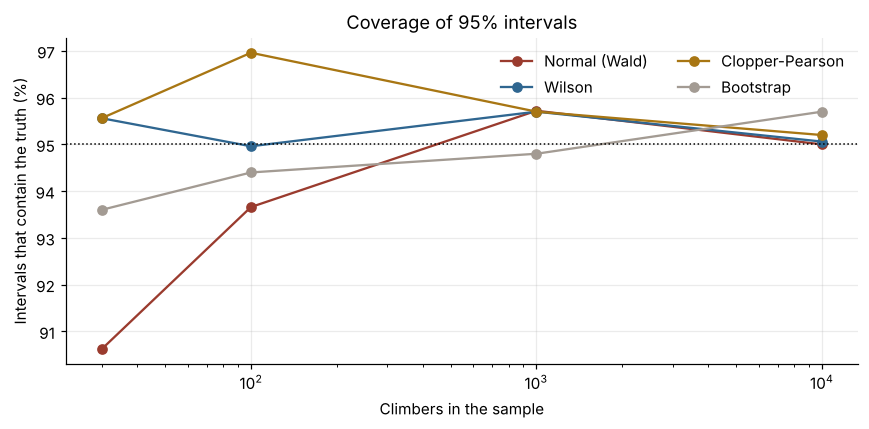

In [3]:
rng = np.random.default_rng(7)
EXPERIMENTS, B = 5000, 1000
sample_sizes = [30, 100, 1000, 10000]
coverage = {m: [] for m in ["Normal (Wald)", "Wilson", "Clopper-Pearson", "Bootstrap"]}

for n in sample_sizes:
    K = rng.binomial(n, TRUTH, EXPERIMENTS)                    # winners in each repeated experiment
    for name, method in [("Normal (Wald)", "normal"), ("Wilson", "wilson"), ("Clopper-Pearson", "beta")]:
        lo, hi = proportion_confint(K, n, alpha=0.05, method=method)
        coverage[name].append(np.mean((lo <= TRUTH) & (TRUTH <= hi)))
    # Bootstrap: resampling a win/loss sample gives Binomial(n, estimate) / n; use the first 1,000 experiments
    resampled = rng.binomial(n, (K[:1000] / n)[:, None], (1000, B)) / n
    lo, hi = np.quantile(resampled, [0.025, 0.975], axis=1)
    coverage["Bootstrap"].append(np.mean((lo <= TRUTH) & (TRUTH <= hi)))

print(f"{'Sample size':<14}" + "".join(f"{n:>10,}" for n in sample_sizes))
for name, vals in coverage.items():
    print(f"{name:<14}" + "".join(f"{v:>10.1%}" for v in vals))

fig, ax = plt.subplots(figsize=(8, 4))
for (name, vals), colour in zip(coverage.items(), [RED, BLUE, GOLD, GREY]):
    ax.plot(sample_sizes, np.array(vals) * 100, "o-", color=colour, label=name)
ax.axhline(95, color="black", ls=":", lw=1)
ax.set_xscale("log"); ax.set_xlabel("Climbers in the sample"); ax.set_ylabel("Intervals that contain the truth (%)")
ax.set_title("Coverage of 95% intervals"); ax.legend(frameon=False, ncol=2); plt.tight_layout(); plt.show()

### How to read it
Each column is a sample size and each row a method. The number is the share of repeated experiments whose interval contained 77.67%. The dotted line on the chart is the 95% promise; points on it keep the promise.

### What it means
At 10,000 climbers every method lands within about a point of 95%, which matches section 2. At only 30 climbers the textbook Normal interval keeps its promise just 90.6% of the time. It is wrong about once in ten tries when it claims to be wrong once in twenty. Wilson (95.6%) is the most accurate there. Clopper-Pearson is a little over 95% at the smaller sizes, that is deliberately cautious. The bootstrap needs a reasonable sample to work well: it is a little low at 30.

**Practical rule:** for a yes/no rate, use Wilson by default; use Clopper-Pearson when being wrong is costly; avoid the Normal formula on small samples. This is why the project's web lab uses Wilson.

### What's next and why
Confidence intervals are one way to say how sure we are. The Bayesian way answers a different, often more natural question: given what I saw, how likely is each possible true chance?

## 4. A Bayesian update

### What we are looking for
A *probability distribution* for the true win chance, not just a range. We start with a prior belief (before seeing data), add the data, and get a posterior belief. For win/loss data the math is clean: a Beta(1, 1) prior (every chance from 0 to 1 equally likely) plus *k* wins in *n* climbers gives a Beta(1 + k, 1 + n - k) posterior. We use sample sizes of 20, 100, 1,000 and 10,000 to watch the belief sharpen.

 Climbers   Wins  Posterior mean      95% credible interval
       20     16          77.27%             58.1% to 91.8%
      100     78          77.45%             68.9% to 85.0%
    1,000    777          77.64%             75.0% to 80.2%
   10,000  7,767          77.66%             76.8% to 78.5%


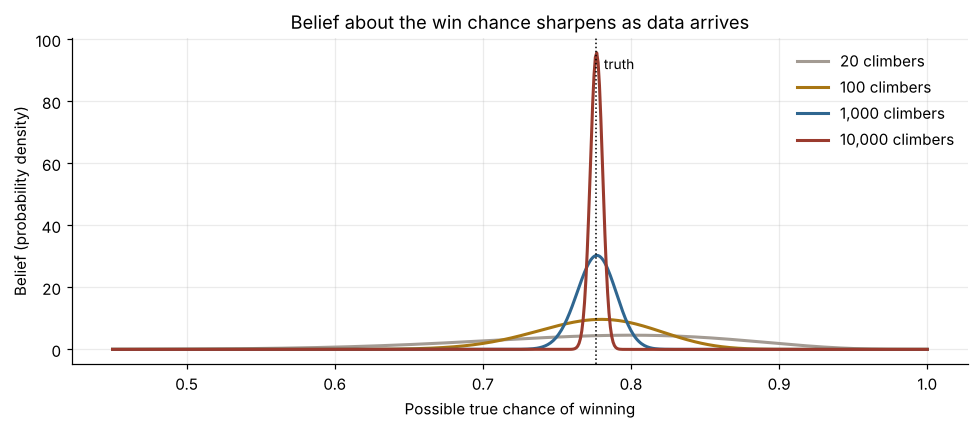

In [4]:
grid = np.linspace(0.45, 1, 600)
fig, ax = plt.subplots(figsize=(9, 4))
print(f"{'Climbers':>9} {'Wins':>6} {'Posterior mean':>15} {'95% credible interval':>26}")
for n, colour in zip([20, 100, 1000, 10000], [GREY, GOLD, BLUE, RED]):
    k = round(n * TRUTH)                                    # a typical result at this size
    post = stats.beta(1 + k, 1 + n - k)
    lo, hi = post.interval(0.95)
    print(f"{n:>9,} {k:>6,} {post.mean():>15.2%} {f'{lo:.1%} to {hi:.1%}':>26}")
    ax.plot(grid, post.pdf(grid), color=colour, lw=2, label=f"{n:,} climbers")
ax.axvline(TRUTH, color="black", ls=":", lw=1); ax.text(TRUTH + 0.005, ax.get_ylim()[1] * 0.9, "truth", fontsize=9)
ax.set_xlabel("Possible true chance of winning"); ax.set_ylabel("Belief (probability density)")
ax.set_title("Belief about the win chance sharpens as data arrives"); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

### How to read it
Each curve is our belief about the true chance after seeing that many climbers. A tall, narrow curve means we are sure; a low, wide one means we are not. The "95% credible interval" in the table is the range containing 95% of the belief.

### What it means
With 20 climbers the belief is spread from 58% to 92%: we know little. With 100 it narrows to 69% to 85%, with 1,000 to 75% to 80%, and with 10,000 to 76.8% to 78.5%. Every curve peaks near the truth, and each one is about three times narrower than the one before it as data grows tenfold, the same square-root rule seen in notebook 02.

A credible interval and a confidence interval look alike but speak differently: the credible interval says "given this data, there's a 95% probability the truth is in here," which is the sentence most people *think* a confidence interval says.

### What's next and why
The Beta(1, 1) prior is a neutral choice. A fair worry is that the prior could steer the answer. We test that now.

## 5. Does the prior matter? (prior sensitivity)

### What we are looking for
Whether a stubborn, wrong prior can survive a lot of data. We give one analyst a badly wrong belief (about 9% chance of winning, worth 22 pretend climbers) and compare to the neutral prior on 20, 100, 1,000 and 10,000 real climbers.

In [5]:
wrong_prior = (2, 20)          # prior mean = 2 / 22 = 9%
print(f"{'Climbers':>9} {'Neutral prior':>15} {'Wrong prior':>13} {'Gap (points)':>14}")
for n in [20, 100, 1000, 10000]:
    k = round(n * TRUTH)
    neutral = stats.beta(1 + k, 1 + n - k).mean()
    biased = stats.beta(wrong_prior[0] + k, wrong_prior[1] + n - k).mean()
    print(f"{n:>9,} {neutral:>15.2%} {biased:>13.2%} {100 * abs(neutral - biased):>14.2f}")

 Climbers   Neutral prior   Wrong prior   Gap (points)
       20          77.27%        42.86%          34.42
      100          77.45%        65.57%          11.88
    1,000          77.64%        76.22%           1.42
   10,000          77.66%        77.52%           0.15


### How to read it
Each row compares the best guess of the two analysts. The last column is how far apart they are.

### What it means
With only 20 climbers the wrong prior drags its holder far off (they say about 43%, against 77% for the neutral prior). With 1,000 climbers the gap is under 2 points, and with 10,000 it is under 0.2. The data overwhelms the prior.

That is the reassuring property of Bayesian methods: **with enough data, two people who start from very different beliefs end up agreeing.** It also warns that with little data the prior does most of the talking, so it should be stated openly.

### What's next and why
So far we estimated one number. Next we test a claim about the whole simulation: does it produce the right *shape* of results, and not only the right average?

## 6. Is the simulation faithful? (goodness-of-fit)

### What we are looking for
Two tests of whether the simulation is working properly.

1. **Is the die fair?** Roll the random number generator a million times. If it is fair each face should come up about one sixth of the time. A chi-square test turns "about" into a probability.
2. **Does the whole spread of finishing steps match the exact answer?** We group the 10,000 climbers into bins of 10 steps and compare the counts with what the exact distribution predicts, again with a chi-square test.

In both tests the *null hypothesis* is "everything is as claimed". A small p-value (below 0.05) would be evidence against it. A large p-value means "no evidence of a problem".

In [6]:
# Test 1: is the random die fair?
rolls = np.random.default_rng(1).integers(1, 7, 1_000_000)
counts = np.bincount(rolls)[1:]
t1 = stats.chisquare(counts)
print("Test 1: one million die rolls")
print("  Faces 1 to 6 counts:", counts.tolist())
print(f"  chi-square = {t1.statistic:.2f}, p-value = {t1.pvalue:.3f}\n")

# Test 2: do the simulated finishing steps match the exact distribution?
ends = paths[:, -1]
exact = exact_distribution(ROLLS, CLUMSY)
edges = [0, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100, 110, 1000]
observed = np.array([((ends >= a) & (ends < b)).sum() for a, b in zip(edges[:-1], edges[1:])])
expected = np.array([exact[a:b].sum() for a, b in zip(edges[:-1], edges[1:])]) * N
t2 = stats.chisquare(observed, expected)
print("Test 2: simulated finishing steps vs exact distribution (10,000 climbers)")
print(f"  {'Steps':<10}{'Observed':>9}{'Expected':>10}")
for a, b, o, e in zip(edges[:-1], edges[1:], observed, expected):
    print(f"  {f'{a}-{b - 1}' if b < 1000 else f'{a}+':<10}{o:>9}{e:>10.1f}")
print(f"  chi-square = {t2.statistic:.2f}, p-value = {t2.pvalue:.3f}  (12 bins, so 11 degrees of freedom)")

Test 1: one million die rolls
  Faces 1 to 6 counts: [166558, 167211, 166275, 166581, 166837, 166538]
  chi-square = 3.09, p-value = 0.687

Test 2: simulated finishing steps vs exact distribution (10,000 climbers)
  Steps      Observed  Expected
  0-9             137     144.8
  10-19           129     131.1
  20-29           141     140.5
  30-39           200     212.9
  40-49           465     492.7
  50-59          1173    1110.9
  60-69          1904    1863.8
  70-79          2229    2205.3
  80-89          1800    1851.8
  90-99          1120    1123.5
  100-109         477     501.8
  110+            225     220.6
  chi-square = 10.16, p-value = 0.516  (12 bins, so 11 degrees of freedom)


### How to read it
Test 1 lists how often each face came up in a million rolls: every count is within a few hundred of the ideal 166,667. Test 2 lists, for each band of steps, how many climbers finished there and how many the exact math expects; again the two columns are close. Each test ends with a p-value.

### What it means
Both p-values are well above 0.05 (about 0.69 for the die and 0.52 for the finishing steps), so neither test finds any evidence of a problem. The die is fair and the full shape of the simulation matches the exact distribution, bin by bin.

Be careful what this *doesn't* say: a large p-value does not prove the simulation is perfect. It says that with this much data no flaw was detectable. With a huge sample, a tiny flaw would show up. That limit is the subject of the next section.

### What's next and why
We now use a test for what tests are really for: deciding whether two settings give different results.

## 7. Is a clumsier climber really worse? (two-proportion test and power)

### What we are looking for
Two experiments with 10,000 climbers each, one with no clumsiness and one with 0.1%, and a two-proportion z-test of the claim "both settings win equally often". Then the question that decides whether a study is worth running: **how many climbers do you need to reliably detect a difference this size?** That is called statistical power. We use the exact win chances to size the difference and `statsmodels` to calculate the sample size for 80% power.

No clumsiness: 83.20%   0.1% clumsiness: 78.22%   difference: 4.98 points
z = 8.92, p-value = 4.5e-19

Comparison                   True difference  Climbers per group for 80% power
0.00% vs 0.10% clumsiness             6.03 pt                             668


0.05% vs 0.10% clumsiness             2.96 pt                           2,956
0.09% vs 0.10% clumsiness             0.58 pt                          79,422


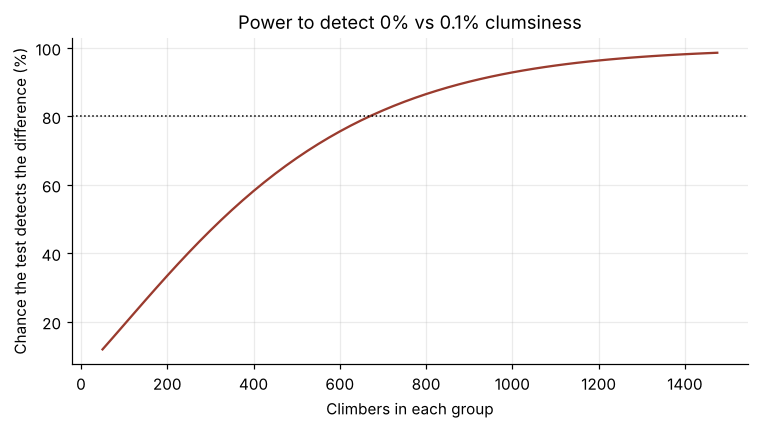

In [7]:
n = 10_000
a = win_chance(simulate(n, ROLLS, 0.0,   seed=1), TARGET)     # no clumsiness
b = win_chance(simulate(n, ROLLS, 0.001, seed=2), TARGET)     # 0.1% clumsiness
z, p = proportions_ztest([round(a * n), round(b * n)], [n, n])
print(f"No clumsiness: {a:.2%}   0.1% clumsiness: {b:.2%}   difference: {100 * (a - b):.2f} points")
print(f"z = {z:.2f}, p-value = {p:.2g}\n")

# Power: how many climbers per group to detect the true difference 80% of the time?
power = NormalIndPower()
print(f"{'Comparison':<28}{'True difference':>16}{'Climbers per group for 80% power':>34}")
for lo_c, hi_c in [(0.0, 0.001), (0.0005, 0.001), (0.0009, 0.001)]:
    p1, p2 = exact_win_chance(ROLLS, TARGET, lo_c), exact_win_chance(ROLLS, TARGET, hi_c)
    need = power.solve_power(proportion_effectsize(p1, p2), power=0.8, alpha=0.05)
    print(f"{f'{lo_c:.2%} vs {hi_c:.2%} clumsiness':<28}{100 * (p1 - p2):>14.2f} pt{need:>32,.0f}")

effect = proportion_effectsize(exact_win_chance(ROLLS, TARGET, 0.0), exact_win_chance(ROLLS, TARGET, 0.001))
sizes = np.arange(50, 1500, 25)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(sizes, [power.power(effect, nobs1=s, alpha=0.05) * 100 for s in sizes], color=RED)
ax.axhline(80, color="black", ls=":", lw=1)
ax.set_xlabel("Climbers in each group"); ax.set_ylabel("Chance the test detects the difference (%)")
ax.set_title("Power to detect 0% vs 0.1% clumsiness"); plt.tight_layout(); plt.show()

### How to read it
The first block is the test itself: the two simulated win rates and a z statistic. The p-value is the probability of a gap this big if the two settings were really the same. The table below it shows how many climbers each group needs to detect the *true* difference 80% of the time; the chart shows the same thing for the first comparison as a curve, power against group size.

### What it means
The two simulated win rates differ by almost 5 points and the p-value is about 4.5e-19, a decisive rejection of "no difference". That is because we used 10,000 climbers per group.

The power table shows the cost of detecting smaller differences. A 6-point gap needs only about 670 climbers per group. Halving the clumsiness difference to 0.05% versus 0.1% (a 3-point gap) needs about 2,960 per group, more than four times as many. A gap of just 0.6 points (0.09% vs 0.1% clumsiness) needs about 79,000 per group. **The smaller the effect, the vastly bigger the sample.** A "not significant" result from a small study mostly means the study was too small to see it.

### What's next and why
One last question about p-values themselves, since the whole section depended on them: what do they do when there is *nothing* to find?

## 8. What a p-value does when nothing is going on (false alarms)

### What we are looking for
Run the same test thousands of times comparing two groups that are, by construction, *identical*: both have the same true win chance. A 5% significance level promises that no more than about 5% of these tests raise a false alarm. We check, and plot all the p-values.

Tests run on identical groups: 5,000
Share with p < 0.05 (false alarms): 5.5%
Share with p < 0.01:                1.3%
Number of false alarms if you test 20 unrelated things at 0.05: about 1
Chance of at least one false alarm in 20 such tests: 64%


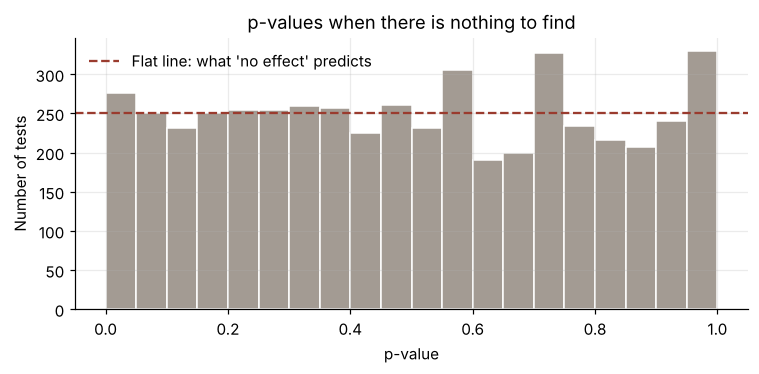

In [8]:
rng = np.random.default_rng(2024)
TESTS, n = 5000, 1000
k1 = rng.binomial(n, TRUTH, TESTS)
k2 = rng.binomial(n, TRUTH, TESTS)                      # same true chance, so there is nothing to find
pvals = np.array([proportions_ztest([x, y], [n, n])[1] for x, y in zip(k1, k2)])

print(f"Tests run on identical groups: {TESTS:,}")
print(f"Share with p < 0.05 (false alarms): {np.mean(pvals < 0.05):.1%}")
print(f"Share with p < 0.01:                {np.mean(pvals < 0.01):.1%}")
print(f"Number of false alarms if you test 20 unrelated things at 0.05: about {20 * 0.05:.0f}")
print(f"Chance of at least one false alarm in 20 such tests: {1 - 0.95 ** 20:.0%}")

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(pvals, bins=20, range=(0, 1), color=GREY, edgecolor="white")
ax.axhline(TESTS / 20, color=RED, ls="--", label="Flat line: what 'no effect' predicts")
ax.set_xlabel("p-value"); ax.set_ylabel("Number of tests"); ax.set_title("p-values when there is nothing to find")
ax.legend(frameon=False); plt.tight_layout(); plt.show()

### How to read it
The histogram has one bar for each 5-point band of p-values from 0 to 1. If there is nothing to find, p-values should be spread evenly, so every bar should be about the same height, close to the red dashed line.

### What it means
About 5.5% of the tests came back "significant" even though the groups were identical, close to the promised 5%, and the bars are roughly flat. (Because the number of climbers is a whole number, the p-values are slightly bumpy rather than perfectly flat.)

This is the foundation of the multiple-testing problem. Test 20 unrelated things and the chance that at least one looks "significant" by luck is 64%. Any analysis that tries many variations and reports only the one that "worked" is not evidence. It is the hidden cost of unreported tests. In this project the comparisons were planned in advance, so the p-values in section 7 can be taken at face value.

### What's next and why
This completes the statistics toolkit. Notebook 04 moves to machine learning: can a model predict, from the current step, who will win, and does it beat the exact answer we now know?

## 9. Summary

| Question | Result | Method |
|---|---|---|
| Win chance from 10,000 climbers | 77.55%, 95% range about 76.7% to 78.4% | Wilson, normal, Clopper-Pearson, bootstrap (all alike at this size) |
| Which interval keeps its 95% promise at n = 30? | Wilson 95.6%, bootstrap 93.6%, Normal 90.6% | Coverage simulation |
| Belief after 10,000 climbers | mean 77.7%, credible interval 76.8% to 78.5% | Beta-Binomial Bayesian update |
| Does a wrong prior survive big data? | No: gap under 0.2 points at 10,000 | Prior sensitivity |
| Is the simulation faithful? | Yes: p = 0.69 (die), p = 0.52 (finishing steps) | Chi-square goodness of fit |
| Does clumsiness matter? | Yes: 83.2% vs 78.2% win, p about 4.5e-19 | Two-proportion z-test |
| Sample size to see a 3-point gap | about 2,960 per group | Power analysis |
| False alarms at the 5% level | 5.5% observed | Repeated null tests |

**Takeaways**
1. Prefer Wilson over the Normal formula for a win rate, especially with small samples.
2. More data helps slowly (square-root rule) but it also washes out a bad prior.
3. A large p-value means "no evidence of a problem," not "proven fine."
4. Detecting small effects needs far more data than detecting large ones.
5. Run many tests and some will look significant by luck.

**Where the code lives:** `src/hacker_stats.py`; the same intervals and tests run in the browser in `docs/lab.html` (cards: bootstrap, Bayesian, tests).